# JDsearch EDA: the history timeline behind the apparent funnel

**Group 3, BT4222 · Full-file audit · 27 October 2026**

The interim report defined our task as re-ranking the displayed products for a held-out search query. The professor then flagged a strange history: carts and orders dramatically outnumber clicks. This notebook traces each of the 26,667,260 earlier actions back from the final query, then turns the finding into feature and evaluation decisions. It is a companion to the existing step 1–7 pipeline. The interim report itself is unchanged.


## 1. Reconstruct age from the interval list

JDsearch aligns historical query, product, action type and time lists by index. The time list has one extra interval, from the last earlier action to the final query. Its first value is zero. For gaps [0, 12, 4, 5], the three actions are 21, 9 and 5 seconds before the query. We divide those cumulative remaining seconds by 86,400. Treating each gap as the action's age would shift old events into the wrong bins.

Across all 173,831 user rows, the first interval is zero and reconstructed ages move monotonically toward the query. The [dataset README](https://github.com/rucliujn/JDsearch) documents the interval structure; the professor's feedback supplies the seconds unit.


In [1]:
from pathlib import Path
import csv, json, subprocess, sys
from IPython.display import SVG, display

# In Colab, mount the team's raw-data folder and fetch the repository if needed.
if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    colab_repo = Path("/content/bt4222-main-recsys")
    if not colab_repo.exists():
        subprocess.run(["git", "clone", "https://github.com/harvestingmoon/bt4222-two-tower-recsys.git",
                        str(colab_repo)], check=True)

locations = [Path.cwd(), Path.cwd().parent, Path.cwd() / "bt4222-two-tower-recsys",
             Path("/content/bt4222-main-recsys")]
REPO = next((p for p in locations if (p / "scripts/01b_history_feedback_eda.py").exists()), None)
if REPO is None:
    raise FileNotFoundError("Run from the updated repository or set REPO to its folder.")
raw_locations = [REPO / "data/raw/user_behavior_data.txt",
                 REPO.parent / "JDsearch/user_behavior_data.txt",
                 Path("/content/drive/MyDrive/bt4222/raw/user_behavior_data.txt")]
USER_FILE = next((p for p in raw_locations if p.is_file()), None)
if USER_FILE is None:
    raise FileNotFoundError("Place user_behavior_data.txt in data/raw or set USER_FILE.")
OUT = REPO / "outputs/history_feedback"
print("Repository:", REPO.name)
print("Raw file:", USER_FILE.name)

Repository: bt4222-two-tower-recsys
Raw file: user_behavior_data.txt


In [2]:
gaps = [0, 12, 4, 5]
ages_seconds = [sum(gaps[i+1:]) for i in range(len(gaps)-1)]
assert ages_seconds == [21, 9, 5]
print("Example ages (seconds):", ages_seconds)
print("Example ages (days):", [round(v/86400, 7) for v in ages_seconds])

Example ages (seconds): [21, 9, 5]
Example ages (days): [0.0002431, 0.0001042, 5.79e-05]


## 2. Reproduce the full-file audit

The streaming scanner validates aligned lists and action labels, then writes a small summary, exact age-bucket table and charts. It reads the raw user file only; the 4.8 GB product metadata file is unnecessary for this temporal question.


In [3]:
subprocess.run([sys.executable, str(REPO / "scripts/01b_history_feedback_eda.py"),
                str(USER_FILE), "--out", str(OUT)], check=True, capture_output=True, text=True)
summary = json.loads((OUT / "summary.json").read_text())
with (OUT / "action_by_age.csv").open(newline="") as f:
    by_age = list(csv.DictReader(f))
assert summary["users"] == 173831 and summary["history_events"] == 26667260
print(f'{summary["users"]:,} users; {summary["history_events"]:,} history events; '
      f'{summary["candidate_impressions"]:,} candidate impressions')

173,831 users; 26,667,260 history events; 15,510,012 candidate impressions


The full history contains **8,298,894 clicks, 11,526,504 carts, 6,817,283 orders and 24,579 follows**. Pooling these different lookback periods gives 0.72 clicks per cart and 1.69 carts per order. Those are ratios of recorded actions, not conversion rates.


## 3. Follow each action backward

The first chart shows action mix within non-overlapping age buckets; the second keeps the absolute counts on a log scale. Reading them together prevents a tiny bucket with a high percentage from looking as influential as a bucket with millions of events.


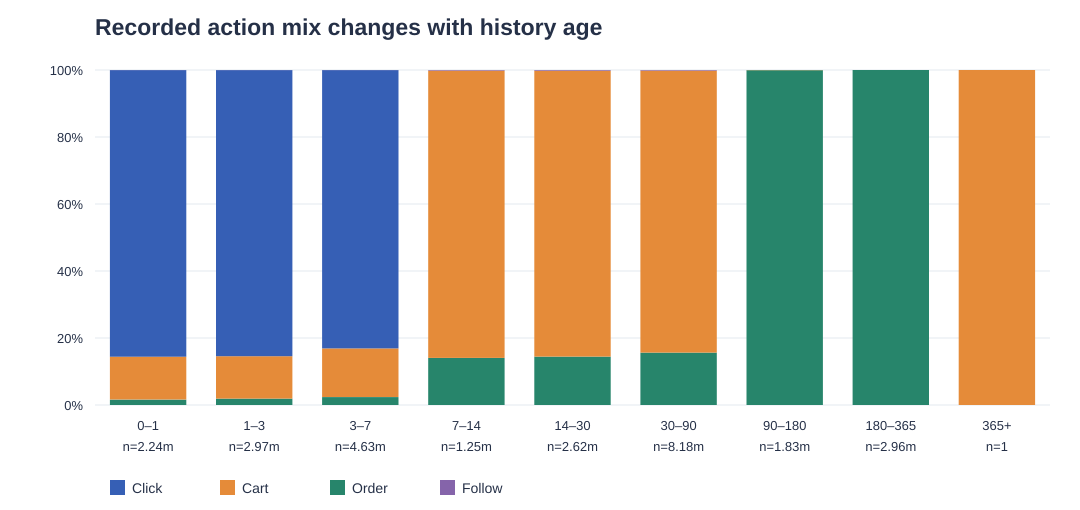

In [4]:
display(SVG(filename=str(OUT / "action_mix.svg")))

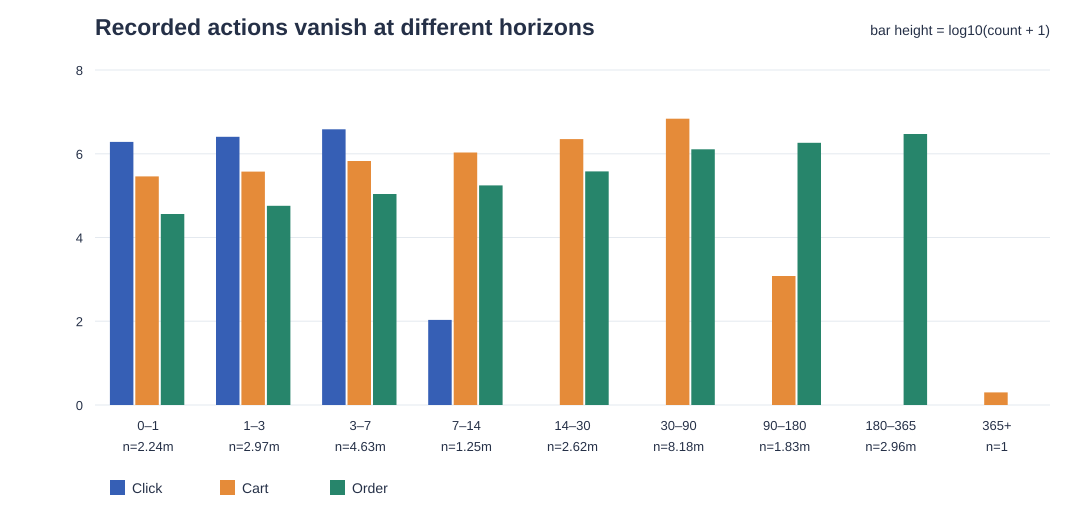

In [5]:
display(SVG(filename=str(OUT / "action_counts.svg")))

**Full-file counts by age**

Age before query | Clicks | Carts | Orders | Click share | Events
--- | ---: | ---: | ---: | ---: | ---:
0–1 days | 1,918,289 | 287,228 | 36,441 | 85.54% | 2,242,574
1–3 days | 2,534,453 | 375,715 | 57,033 | 85.40% | 2,967,830
3–7 days | 3,846,045 | 672,214 | 109,348 | 83.09% | 4,629,013
7–14 days | 107 | 1,068,418 | 175,040 | 0.01% | 1,245,775
14–30 days | 0 | 2,232,532 | 377,968 | 0.00% | 2,615,709
30–90 days | 0 | 6,889,193 | 1,280,095 | 0.00% | 8,183,797
90–180 days | 0 | 1,203 | 1,824,126 | 0.00% | 1,825,329
180–365 days | 0 | 0 | 2,957,232 | 0.00% | 2,957,232
365+ days | 0 | 1 | 0 | 0.00% | 1


The click cliff is abrupt: days 3–7 contain 3,846,045 clicks; days 7–14 contain **107**; later buckets contain none. Carts remain common until day 90. After day 90, almost every retained action is an order.

This is consistent with different recording or retention horizons: about 7 days for clicks, 90 for carts and follows, and 365 for orders. These are empirical boundaries, not a documented platform policy. We keep the exceptions in view: 107 clicks are at least 7 days old, 1,204 carts are at least 90 days old, and one cart is older than 365 days.


In [6]:
for action in ("CLICK", "CART", "ORD", "FLW"):
    a = summary["type_age"][action]
    print(f'{action:5} n={a["events"]:>10,}  median={a["age_days_p50"]:>7.2f}d'
          f'  p99={a["age_days_p99"]:>7.2f}d'
          f'  <7d={100*a["share_before_7d"]:>6.3f}%'
          f'  <90d={100*a["share_before_90d"]:>6.3f}%')

CLICK n= 8,298,894  median=   2.79d  p99=   6.49d  <7d=99.999%  <90d=100.000%
CART  n=11,526,504  median=  38.37d  p99=  88.31d  <7d=11.583%  <90d=99.990%
ORD   n= 6,817,283  median= 154.08d  p99= 359.58d  <7d= 2.975%  <90d=29.864%
FLW   n=    24,579  median=  39.44d  p99=  87.70d  <7d=10.786%  <90d=100.000%


## 4. What happens to the apparent funnel?

On a common 0–7 day window, the data have **6.22 clicks per cart** and **6.58 carts per order**. The first fits the professor's rough 5:1–10:1 reference range. The second is above the 3:1–5:1 reference range. The huge change from the all-history ratios explains the puzzle without assuming unusual shoppers. Even the seven-day ratios cannot measure conversion: the file does not link individual click → cart → order journeys.

There are **25,432 users with a recorded order but no recorded click**. Most orders come from months when clicks are almost absent. We therefore cannot interpret these users as people who purchased without ever clicking.


In [7]:
h = summary["history_action_counts"]
w = summary["history_action_0_7d"]
print(f'All history: clicks/cart={h["CLICK"]/h["CART"]:.2f}; carts/order={h["CART"]/h["ORD"]:.2f}')
print(f'0–7 days:   clicks/cart={w["CLICK"]/w["CART"]:.2f}; carts/order={w["CART"]/w["ORD"]:.2f}')
print(f'Users with no click: {summary["users_without_click"]:,}')
print(f'Users with an order but no click: {summary["users_with_order_but_no_click"]:,}')
print(f'Correlation of user click fraction with share of events under 7 days: '
      f'{summary["click_share_recent_share_correlation"]:.3f}')

All history: clicks/cart=0.72; carts/order=1.69
0–7 days:   clicks/cart=6.22; carts/order=6.58
Users with no click: 28,184
Users with an order but no click: 25,432
Correlation of user click fraction with share of events under 7 days: 0.953


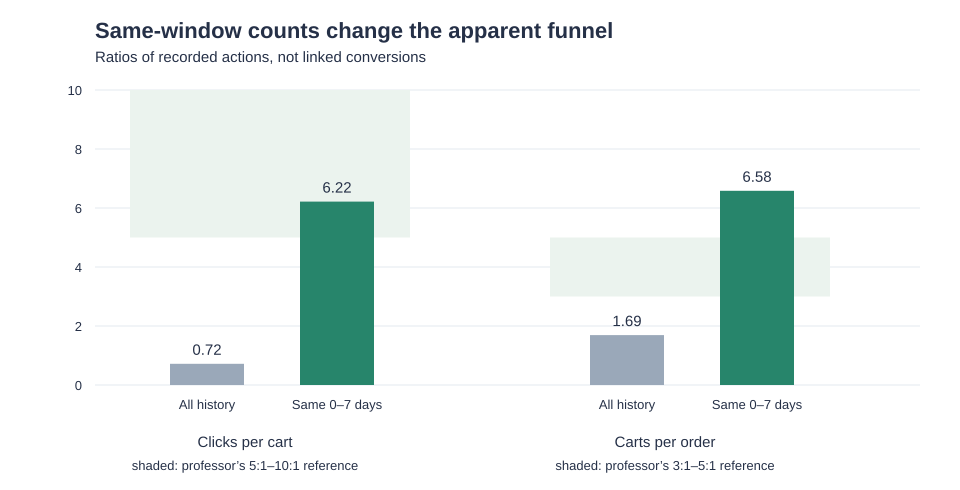

In [8]:
display(SVG(filename=str(OUT / "window_ratios.svg")))

The raw per-user click fraction is strongly associated with the fraction of their retained events from the last week (Pearson r = **0.953**). The empty upper-left triangle in the chart is largely imposed by the data: almost every click is recent, so the click fraction can seldom exceed the recent-history fraction. A model could learn this extraction window from the ratio and mistake it for a stable preference. The windowed-feature ablation tests whether keeping action types and age ranges separate helps on held-out users.


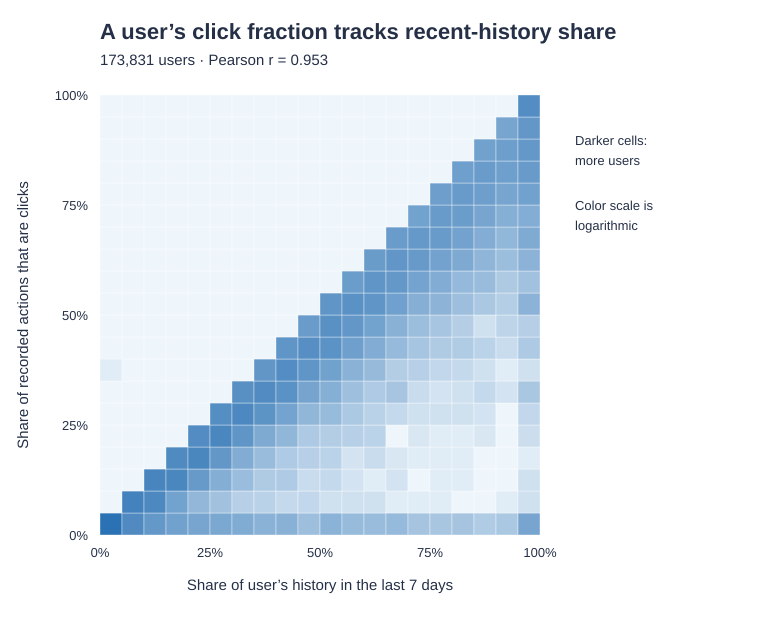

In [9]:
display(SVG(filename=str(OUT / "recent_click_density.svg")))

## 5. The fields have different jobs

| Field | Use | Boundary |
| --- | --- | --- |
| Final query, displayed candidates, labels | Supervised, query-conditioned full-slate re-ranking | Labels exist only for displayed items; unshown products have unknown outcomes. |
| User's earlier actions | Personal preference | Preserve type and comparable age window. |
| Earlier query attached to an action | Query → item evidence | Queryless history needs a fallback. |
| Earlier actions from all users | Item and attribute popularity | Use only pre-query actions; keep candidate labels out of these counts. |
| Product title, brand, categories, shop | Lexical and attribute signals for sparse-history products | Terms are anonymised; metadata can be missing. |
| Candidate labels from other training users | Impression rate features | Compute out of fold for train; fit on train only for validation/test. |

Only **28.3% of clicks**, **31.1% of carts** and **51.0% of orders** have a recorded history query. The original course notebook noticed the -1 marker; these full-file figures show why the query-conditioned model cannot discard queryless actions.


## 6. Choices to test in modelling

Use click counts and recency inside 7 days, cart counts inside 7 and 90 days, and order counts inside 7, 90 and 365 days. Keep action type and age in separate channels. Beyond the click horizon, zero observed clicks means the click log is mostly absent there; avoid a single click/cart fraction over the full history. The repository already encodes these windows in configs/default.yaml, splits the two-tower user's history into short, middle and long segments, and has a window ablation in step 4.

Keep the interim task fixed: score every product in the displayed slate for the final query. Query and item metadata represent content; earlier actions represent personal preference. Compare the two-tower score and the LightGBM re-ranker with simple lexical and popularity baselines on the **same full slates**. Report MRR, NDCG@10 and graded NDCG@10, plus slices by history length, latest-event age and item history coverage. Select settings on validation users and use the held-out test split for the final comparison.

The original candidate order leaks the target: all 171,728 slates with a positive label place positives in a prefix. The order is not a trustworthy display-position field and must stay out of model inputs.


## Final report handoff

The 2026–27 deliverable guideline asks Section 1 to show what changed after the interim report and which new signals shaped feature engineering. The evidence here is the full-file timeline, the controlled seven-day comparison, the user-level confound and the field-role table. For the final report, pair this evidence with the existing step 4 window ablation: the EDA motivates a design; only held-out ranking results can show whether it helps. The model-performance outputs belong to the later stage notebooks and are not produced by this EDA notebook.

## Provenance and limits

The raw JDsearch user file supplied with the group project was scanned in full. The [JDsearch README](https://github.com/rucliujn/JDsearch) defines the aligned lists and candidate labels; the professor's feedback clarifies seconds. The group's revised interim report and course JDSearch_Data_Anlaysis.ipynb informed the questions, while the counts here were recomputed. This notebook supports the deliverable guideline's Section 1 requirement for new data understanding and feature engineering without revising the interim report.

The dataset lacks linked action journeys and absolute timestamps for this analysis. Age-bucket action ratios are descriptive, and the approximate retention windows are inferences from the observed file.